# Practice 07 — DL Training Pipeline

**Goal:** build the mini-batch training pipeline once, then reuse it to compare two models.

| Stage | What it produces |
|:---|:---|
| Data | train / validation / test split, standardized, wrapped in `DataLoader` |
| Model | an `nn.Module` returning logits |
| Loss + optimizer | `nn.CrossEntropyLoss`, `torch.optim.Adam` |
| `train` / `evaluate` | the epoch loop and the no-grad evaluation, written once |
| Diagnostics | learning curves, final test score, confusion matrix |

- Steps 0–7 → the pipeline; Steps 8–11 → a plain MLP vs. the same MLP with four added techniques
- Data → `load_digits`: 1797 digits, $8 \times 8$ pixels flattened to 64 features, labels 0–9

---
## Step 0. Imports and Setup

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import TensorDataset, DataLoader

np.random.seed(42)
torch.manual_seed(42)

plt.rcParams['axes.unicode_minus'] = False

# every tensor and every module is moved to this device; on a CPU-only machine .to(device) is a no-op
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cuda


---
## Step 1. Data — Split, Then Standardize

| Set | In the training loop | Role |
|:---|:---|:---|
| Train (60%) | every batch | updates the weights |
| Validation (20%) | once per epoch | monitors generalization |
| Test (20%) | never | scored once, at the end |

In [2]:
digits = load_digits()
X = digits.data                 # (1797, 64) pixel intensities, 0-16
y = digits.target               # (1797,) labels 0-9

print(f'X: {X.shape}, y: {y.shape}, classes: {np.unique(y)}')
display(pd.DataFrame(X, columns=[f'pixel_{i}' for i in range(X.shape[1])]).head(10))

X: (1797, 64), y: (1797,), classes: [0 1 2 3 4 5 6 7 8 9]


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_54,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,5.0,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,9.0,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0
5,0.0,0.0,12.0,10.0,0.0,0.0,0.0,0.0,0.0,0.0,...,4.0,0.0,0.0,0.0,9.0,16.0,16.0,10.0,0.0,0.0
6,0.0,0.0,0.0,12.0,13.0,0.0,0.0,0.0,0.0,0.0,...,8.0,0.0,0.0,0.0,1.0,9.0,15.0,11.0,3.0,0.0
7,0.0,0.0,7.0,8.0,13.0,16.0,15.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,13.0,5.0,0.0,0.0,0.0,0.0
8,0.0,0.0,9.0,14.0,8.0,1.0,0.0,0.0,0.0,0.0,...,8.0,0.0,0.0,0.0,11.0,16.0,15.0,11.0,1.0,0.0
9,0.0,0.0,11.0,12.0,0.0,0.0,0.0,0.0,0.0,2.0,...,4.0,0.0,0.0,0.0,9.0,12.0,13.0,3.0,0.0,0.0


$$x_i^{\text{new}} = \frac{x_i - \mu_i}{\sigma_i}$$

- **Split first** → statistics taken before the split leak test information into training
- $\sigma_i = 0$ → use 1, so nothing is divided by zero

In [3]:
# 60 / 20 / 20 split, stratified so every class keeps its proportion
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

train_mean = X_train.mean(axis=0)
train_std  = X_train.std(axis=0)
train_std[train_std == 0] = 1.0   # leave zero-variance features unscaled

X_train = (X_train - train_mean) / train_std
X_val   = (X_val   - train_mean) / train_std   # statistics from the training set
X_test  = (X_test  - train_mean) / train_std   # statistics from the training set

print(f'Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}')
print(f'constant pixels in the training set: {(train_std == 1.0).sum()}')
print(f'train mean/std after scaling: {X_train.mean():.4f} / {X_train.std():.4f}')

Train: (1078, 64), Val: (359, 64), Test: (360, 64)
constant pixels in the training set: 4
train mean/std after scaling: 0.0000 / 0.9682


- Std 0.968, not 1 → the 4 constant pixels stay at 0: $\sqrt{60/64}$

---
## Step 2. `TensorDataset` and `DataLoader`

| Term | Meaning | Here |
|:---|:---|:---|
| Batch size | samples per weight update | 16 |
| Iteration | one weight update | one batch |
| Epoch | one pass over the training set | 68 iterations, $\lceil 1078/16 \rceil$ |

- `TensorDataset` pairs inputs with labels, `DataLoader` batches them
- Labels → `LongTensor`, for `CrossEntropyLoss`
- `shuffle=False` for validation, test → `y_pred` keeps the order of `y_val`, `y_test`

In [4]:
train_loader = DataLoader(
    TensorDataset(torch.FloatTensor(X_train), torch.LongTensor(y_train)),
    batch_size=16, shuffle=True)
val_loader = DataLoader(
    TensorDataset(torch.FloatTensor(X_val), torch.LongTensor(y_val)),
    batch_size=16, shuffle=False)
test_loader = DataLoader(
    TensorDataset(torch.FloatTensor(X_test), torch.LongTensor(y_test)),
    batch_size=16, shuffle=False)

print(f'batches per epoch - train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}')

X_batch, Y_batch = next(iter(train_loader))
print(f'one batch - X {tuple(X_batch.shape)} {X_batch.dtype}, Y {tuple(Y_batch.shape)} {Y_batch.dtype}')

batches per epoch - train: 68, val: 23, test: 23
one batch - X (16, 64) torch.float32, Y (16,) torch.int64


---
## Step 3. Model

- MLP → $64 \to 128 \to 128 \to 10$
- `nn.CrossEntropyLoss` applies the softmax → the model returns raw **logits**, no final activation
- Model `.to(device)` first, then the optimizer

In [5]:
class DigitMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(64, 128), nn.ReLU(),
            nn.Linear(128, 128), nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        z = self.net(x)      # logits; the softmax is applied inside the loss
        return z


torch.manual_seed(42)
model_baseline = DigitMLP().to(device)
print(model_baseline)
print()
print(f'Total parameters: {sum(p.numel() for p in model_baseline.parameters()):,}')

DigitMLP(
  (net): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

Total parameters: 26,122


---
## Step 4. Loss and Optimizer

$$o_k = \frac{e^{z_k}}{\sum_q e^{z_q}}, \qquad J = -\log o_{y}$$

- $z$ = logits, $y$ = the true class → `nn.CrossEntropyLoss` does softmax + negative log-likelihood in one call
- Adam → per-parameter step size, from running averages of the gradient and its square
- `lr=rho` → learning rate $\rho$; `lr` is the API's name for it

In [6]:
rho    = 0.001
epochs = 50

optimizer_baseline = torch.optim.Adam(model_baseline.parameters(), lr=rho)

print(f'Loss      : {nn.CrossEntropyLoss()}')
print(f'Optimizer : Adam (lr = {rho})')
print(f'Epochs    : {epochs}')

Loss      : CrossEntropyLoss()
Optimizer : Adam (lr = 0.001)
Epochs    : 50


---
## Step 5. `train` and `evaluate`

| Function | Does | Returns |
|:---|:---|:---|
| `evaluate(model, loader, device)` | one pass, gradients off | `(loss, accuracy, y_pred)` |
| `train(model, train_loader, val_loader, optimizer, epochs, device)` | epoch loop + `evaluate` per epoch | `(train_losses, train_accs, val_losses, val_accs)` |

- Only `val_loader` inside `train` → test data that steers training stops measuring generalization
- `model.train()`, `model.eval()` → train / eval mode of dropout and batch normalization, set inside the functions

In [7]:
def evaluate(model, loader, device):
    model.eval()
    criterion = nn.CrossEntropyLoss()
    loss_sum, correct, count = 0.0, 0, 0
    preds = []
    with torch.no_grad():
        for X_batch, Y_batch in loader:
            X_batch = X_batch.to(device)
            Y_batch = Y_batch.to(device)

            output = model(X_batch)
            loss_sum += criterion(output, Y_batch).item()
            correct += (output.argmax(1) == Y_batch).sum().item()
            count += len(Y_batch)
            preds.append(output.argmax(1).cpu())

    y_pred = torch.cat(preds).numpy()
    return loss_sum / len(loader), correct / count, y_pred

In [8]:
def train(model, train_loader, val_loader, optimizer, epochs, device):
    criterion = nn.CrossEntropyLoss()
    train_losses, train_accs, val_losses, val_accs = [], [], [], []
    for epoch in range(epochs):
        model.train()
        loss_sum, correct, count = 0.0, 0, 0
        for X_batch, Y_batch in train_loader:
            X_batch = X_batch.to(device)
            Y_batch = Y_batch.to(device)

            output = model(X_batch)               # logits, (batch, 10)
            loss = criterion(output, Y_batch)

            optimizer.zero_grad()                 # clear the accumulated gradients
            loss.backward()                       # autograd computes the gradients
            optimizer.step()                      # the optimizer updates the parameters

            loss_sum += loss.item()
            correct += (output.argmax(1) == Y_batch).sum().item()
            count += len(Y_batch)

        train_loss = loss_sum / len(train_loader)
        train_acc = correct / count
        val_loss, val_acc, _ = evaluate(model, val_loader, device)

        train_losses.append(train_loss)
        train_accs.append(train_acc)
        val_losses.append(val_loss)
        val_accs.append(val_acc)

        if epoch == 0 or (epoch + 1) % 10 == 0:
            print(f'  Epoch {epoch+1:3d}/{epochs}  '
                  f'train_loss={train_loss:.4f}  val_loss={val_loss:.4f}  '
                  f'train_acc={train_acc:.4f}  val_acc={val_acc:.4f}')
    return train_losses, train_accs, val_losses, val_accs

---
## Step 6. Training the Baseline

- The whole pipeline → one call

In [9]:
torch.manual_seed(42)   # train_loader shuffles from the same state for both models
train_losses_baseline, train_accs_baseline, val_losses_baseline, val_accs_baseline = train(
    model_baseline, train_loader, val_loader, optimizer_baseline, epochs=epochs, device=device)

print()
print(f'Baseline final  train_loss={train_losses_baseline[-1]:.4f}  val_loss={val_losses_baseline[-1]:.4f}  '
      f'train_acc={train_accs_baseline[-1]:.4f}  val_acc={val_accs_baseline[-1]:.4f}')

  Epoch   1/50  train_loss=1.4446  val_loss=0.5248  train_acc=0.6633  val_acc=0.8802


  Epoch  10/50  train_loss=0.0063  val_loss=0.0868  train_acc=1.0000  val_acc=0.9749


  Epoch  20/50  train_loss=0.0012  val_loss=0.0936  train_acc=1.0000  val_acc=0.9721


  Epoch  30/50  train_loss=0.0004  val_loss=0.0999  train_acc=1.0000  val_acc=0.9721


  Epoch  40/50  train_loss=0.0002  val_loss=0.1040  train_acc=1.0000  val_acc=0.9721


  Epoch  50/50  train_loss=0.0001  val_loss=0.1089  train_acc=1.0000  val_acc=0.9721

Baseline final  train_loss=0.0001  val_loss=0.1089  train_acc=1.0000  val_acc=0.9721


---
## Step 7. Learning Curves

- Train loss = average over the epoch, while the weights were still changing → at epoch 1 it lies above the validation loss

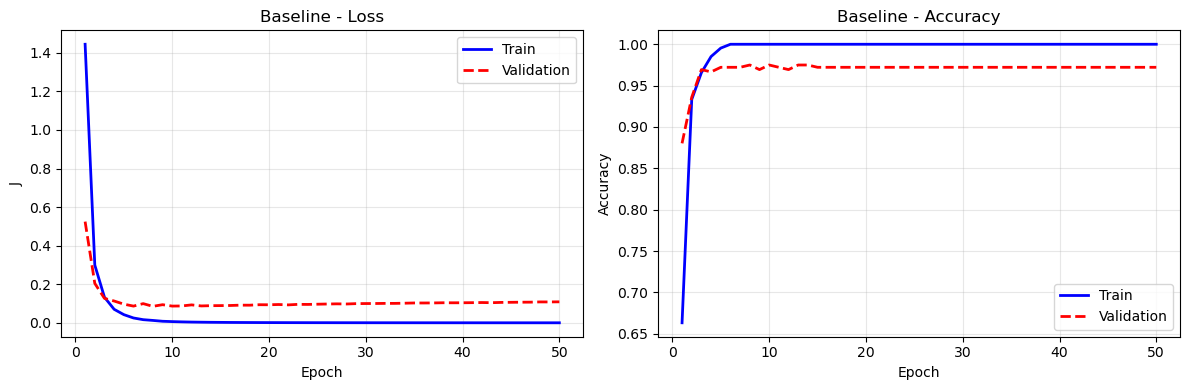

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs_range = range(1, epochs + 1)

axes[0].plot(epochs_range, train_losses_baseline, 'b-',  linewidth=2, label='Train')
axes[0].plot(epochs_range, val_losses_baseline,   'r--', linewidth=2, label='Validation')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('J')
axes[0].set_title('Baseline - Loss'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, train_accs_baseline, 'b-',  linewidth=2, label='Train')
axes[1].plot(epochs_range, val_accs_baseline,   'r--', linewidth=2, label='Validation')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].set_title('Baseline - Accuracy'); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

- Training loss → 0.0001; validation loss 0.087 at epoch 10, 0.109 at epoch 50 → the widening gap is **overfitting**

---
## Step 8. An Improved Model

| Added | What it does | Baseline |
|:---|:---|:---|
| He (Kaiming normal) initialization | weight std $\sqrt{2/n_{\text{in}}}$ ($n_{\text{in}}$ inputs), matched to ReLU | PyTorch default |
| `nn.BatchNorm1d(128)` | standardizes pre-activations over the batch | none |
| `nn.Dropout(0.3)` | randomly zeroes 30% of units while training | none |
| Weight decay $\lambda = 10^{-3}$ | adds $\lambda\mathbf{w}$ to the gradient, i.e. a $\tfrac{\lambda}{2}\lVert\mathbf{w}\rVert_2^2$ penalty, via `weight_decay` | 0 |

- **Fixed** → loaders, widths, Adam at $\rho = 0.001$, batch size, epochs, `torch.manual_seed(42)` before construction and before training
- Four changes at once → shows what the **group** is worth, not each member

In [11]:
class DigitMLPImproved(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(64, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 10),
        )
        # He initialization, matched to the ReLU that follows each linear layer
        for layer in self.net:
            if isinstance(layer, nn.Linear):
                nn.init.kaiming_normal_(layer.weight, nonlinearity='relu')

    def forward(self, x):
        z = self.net(x)
        return z


torch.manual_seed(42)
model_improved = DigitMLPImproved().to(device)
optimizer_improved = torch.optim.Adam(model_improved.parameters(), lr=rho, weight_decay=1e-3)

print(model_improved)
print()
print(f'Total parameters: {sum(p.numel() for p in model_improved.parameters()):,}')

DigitMLPImproved(
  (net): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=128, out_features=10, bias=True)
  )
)

Total parameters: 26,634


In [12]:
torch.manual_seed(42)   # train_loader shuffles from the same state for both models
train_losses_improved, train_accs_improved, val_losses_improved, val_accs_improved = train(
    model_improved, train_loader, val_loader, optimizer_improved, epochs=epochs, device=device)

print()
print(f'Improved final  train_loss={train_losses_improved[-1]:.4f}  val_loss={val_losses_improved[-1]:.4f}  '
      f'train_acc={train_accs_improved[-1]:.4f}  val_acc={val_accs_improved[-1]:.4f}')

  Epoch   1/50  train_loss=1.8957  val_loss=0.9456  train_acc=0.3664  val_acc=0.8635


  Epoch  10/50  train_loss=0.2457  val_loss=0.1312  train_acc=0.9258  val_acc=0.9721


  Epoch  20/50  train_loss=0.1799  val_loss=0.0937  train_acc=0.9416  val_acc=0.9777


  Epoch  30/50  train_loss=0.1193  val_loss=0.0719  train_acc=0.9629  val_acc=0.9805


  Epoch  40/50  train_loss=0.0860  val_loss=0.0810  train_acc=0.9759  val_acc=0.9805


  Epoch  50/50  train_loss=0.0819  val_loss=0.0922  train_acc=0.9787  val_acc=0.9721

Improved final  train_loss=0.0819  val_loss=0.0922  train_acc=0.9787  val_acc=0.9721


- Train loss above validation loss at every printed epoch up to 40 (0.246 vs. 0.131 at epoch 10) → mostly dropout: on in `model.train()`, off in `model.eval()`

---
## Step 9. Baseline vs. Improved

- Validation curves only → the ones that measure generalization

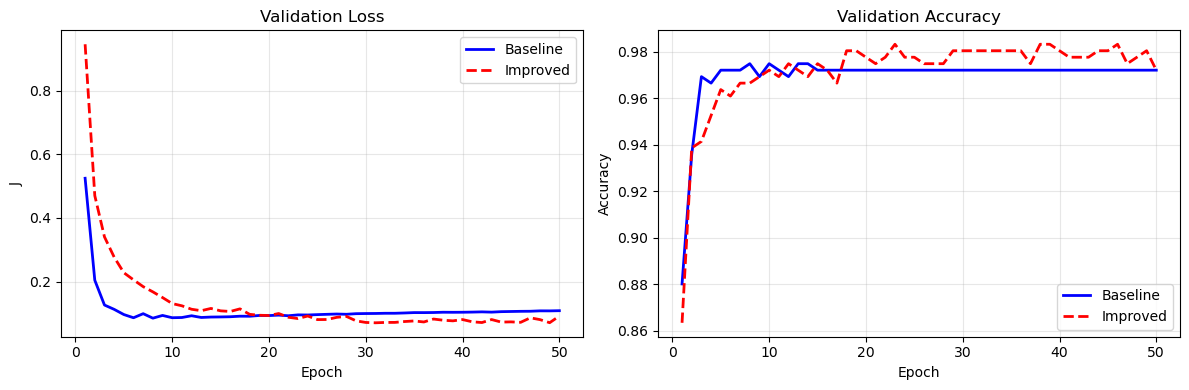

best val_acc  - baseline: 0.9749, improved: 0.9833
final val_loss - baseline: 0.1089, improved: 0.0922


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, val_losses_baseline, 'b-',  linewidth=2, label='Baseline')
axes[0].plot(epochs_range, val_losses_improved, 'r--', linewidth=2, label='Improved')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('J')
axes[0].set_title('Validation Loss'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, val_accs_baseline, 'b-',  linewidth=2, label='Baseline')
axes[1].plot(epochs_range, val_accs_improved, 'r--', linewidth=2, label='Improved')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].set_title('Validation Accuracy'); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout(); plt.show()

print(f'best val_acc  - baseline: {max(val_accs_baseline):.4f}, improved: {max(val_accs_improved):.4f}')
print(f'final val_loss - baseline: {val_losses_baseline[-1]:.4f}, improved: {val_losses_improved[-1]:.4f}')

- Validation loss → the improved model passes the baseline near epoch 20 and ends lower, 0.092 vs. 0.109
- Validation accuracy → within about one percentage point (four samples) of each other from epoch 5 on; equal at the end, 0.972

---
## Step 10. Final Test Evaluation

- Training is over, no choice depends on these numbers → read the test set now, once per model

In [14]:
test_loss_baseline, test_acc_baseline, y_pred_baseline = evaluate(model_baseline, test_loader, device)
test_loss_improved, test_acc_improved, y_pred_improved = evaluate(model_improved, test_loader, device)

print(f'Baseline  test_loss={test_loss_baseline:.4f}  test_acc={test_acc_baseline:.4f}')
print(f'Improved  test_loss={test_loss_improved:.4f}  test_acc={test_acc_improved:.4f}')

Baseline  test_loss=0.1183  test_acc=0.9778
Improved  test_loss=0.1230  test_acc=0.9667


- 360 test samples → one sample = 0.28 percentage points; baseline 0.978 vs. improved 0.967 is four samples, too few to rank the two
- Test loss 0.118 (baseline) vs. 0.123 (improved) → the improved model's lower validation loss does not show on this split

---
## Step 11. Where the Errors Are

- Accuracy counts the errors, it does not locate them → reuse the improved model's `y_pred` from `evaluate`
- Confusion matrix → off-diagonal entries name the digit pairs being confused

misclassified: 12 of 360 test samples


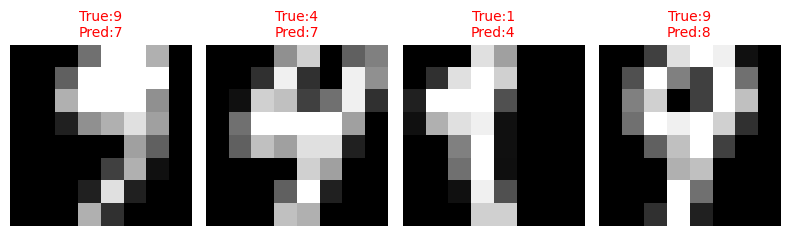

In [15]:
# undo the standardization to recover the original 0-16 pixel scale for display
X_test_display = X_test * train_std + train_mean
wrong_index = np.where(y_pred_improved != y_test)[0]
print(f'misclassified: {len(wrong_index)} of {len(y_test)} test samples')

fig, axes = plt.subplots(1, 4, figsize=(8, 2.5))
for i in range(4):
    axes[i].axis('off')
    if i < len(wrong_index):      # with fewer than four errors the remaining panels stay empty
        index = wrong_index[i]
        axes[i].imshow(X_test_display[index].reshape(8, 8), cmap='gray')
        axes[i].set_title(f'True:{y_test[index]}\nPred:{y_pred_improved[index]}', color='red', fontsize=10)
plt.tight_layout(); plt.show()

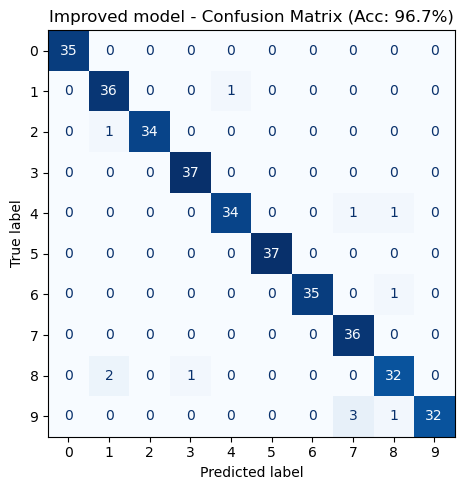

In [16]:
fig, ax = plt.subplots(figsize=(6, 5))
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test, y_pred_improved), display_labels=range(10))
display_matrix.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Improved model - Confusion Matrix (Acc: {test_acc_improved:.1%})')
plt.tight_layout(); plt.show()

- 12 errors in 360 → the largest off-diagonal entry: three 9s read as 7

---
## Summary

- Validation → read every epoch, used to compare the models; test → read once, after every choice is made
- `train` / `evaluate` name neither model nor dataset → the second model needed no new training code
- The four techniques, as a group → lower validation loss (0.092 vs. 0.109), yet 360 test samples cannot rank the two

---
## Exercises

1. `batch_size=4`, then `256`, in the three loaders — what changes: iterations per epoch, run time, loss curve?
2. `torch.optim.SGD(..., lr=rho)` — how many epochs to reach Adam's 50-epoch result?
3. Enable the four techniques one at a time — which matters most?
4. Baseline on 10% of the training set — what do the two loss curves do?

In [17]:
# Write your code here